# Bài 2 · Hiệu ứng quang điện
*Episode 2 · The photoelectric effect*

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JasonDE03/sophon/blob/main/lab/02_photoelectric.ipynb)

Từ năng lượng của một photon đến phép đo hằng số Planck: hãy chạy lần lượt các ô để tự kiểm chứng phương trình Einstein.
*From the energy of one photon to a measurement of Planck's constant: run the cells in order to test Einstein's equation yourself.*

## 1. Một photon có đủ năng lượng không?
*Does one photon have enough energy?*

Với bước sóng $\lambda$, năng lượng photon là $E=h\nu=hc/\lambda$; nếu $E>\phi$, động năng cực đại là $K_{\max}=E-\phi$. Kiểm tra kẽm có công thoát $4{,}33$ eV dưới ánh sáng $253{,}7$ nm; chia năng lượng theo joule cho điện tích nguyên tố $e$ để đổi sang eV.
*For wavelength $\lambda$, the photon energy is $E=h\nu=hc/\lambda$; if $E>\phi$, the maximum kinetic energy is $K_{\max}=E-\phi$. Check zinc with work function $4.33$ eV under $253.7$ nm light; divide energy in joules by the elementary charge $e$ to convert to eV.*

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from scipy.constants import h, e, c

h_ev = h / e  # Planck's constant in eV s.
wavelength = 253.7e-9  # Wavelength in metres.
photon_ev = h_ev * c / wavelength
kmax_ev = max(0, photon_ev - 4.33)
assert abs(photon_ev - 4.887) < 0.005
assert abs(kmax_ev - 0.557) < 0.005
print(f"Zn / 253.7 nm: photon = {photon_ev:.6f} eV, Kmax = {kmax_ev:.6f} eV")

Zn / 253.7 nm: photon = 4.887040 eV, Kmax = 0.557040 eV


## 2. Kim loại nào phát electron dưới ánh sáng nhìn thấy?
*Which metals emit electrons under visible light?*

Tần số ngưỡng là $\nu_0=\phi/h$, tương ứng với bước sóng ngưỡng $\lambda_0=hc/\phi$; muốn electron có động năng dương, cần $\lambda<\lambda_0$. Dùng cùng các giá trị công thoát gần đúng và khoảng nhìn thấy 380–750 nm như mô phỏng: Cs, K và Na bứt được electron với một phần ánh sáng nhìn thấy; Zn, Cu và Pt cần tia tử ngoại. Công thoát thực tế phụ thuộc bề mặt kim loại.
*The threshold frequency is $\nu_0=\phi/h$, corresponding to threshold wavelength $\lambda_0=hc/\phi$; positive electron kinetic energy requires $\lambda<\lambda_0$. Using the simulation's approximate work functions and visible range of 380–750 nm, Cs, K, and Na respond to part of this range; Zn, Cu, and Pt need ultraviolet light. Actual work functions depend on the metal surface.*

In [2]:
# Same approximate work functions as METALS in sims/photoelectric.js (eV).
METALS = {"Cs": 2.14, "K": 2.29, "Na": 2.75, "Zn": 4.33, "Cu": 4.65, "Pt": 5.64}
visible_min_nm, visible_max_nm = 380, 750
print(f"{'Metal':<6} {'Work function (eV)':>18} {'Threshold (nm)':>16}  Visible response (380-750 nm)")
for metal, work_function_ev in METALS.items():
    threshold_nm = h_ev * c / work_function_ev * 1e9
    visible_upper_nm = min(threshold_nm, visible_max_nm)
    response = f"Yes: {visible_min_nm} <= wavelength < {visible_upper_nm:.1f} nm" if threshold_nm > visible_min_nm else "No: ultraviolet needed"
    print(f"{metal:<6} {work_function_ev:>18.2f} {threshold_nm:>16.1f}  {response}")

Metal  Work function (eV)   Threshold (nm)  Visible response (380-750 nm)
Cs                   2.14            579.4  Yes: 380 <= wavelength < 579.4 nm
K                    2.29            541.4  Yes: 380 <= wavelength < 541.4 nm
Na                   2.75            450.9  Yes: 380 <= wavelength < 450.9 nm
Zn                   4.33            286.3  No: ultraviolet needed
Cu                   4.65            266.6  No: ultraviolet needed
Pt                   5.64            219.8  No: ultraviolet needed


## 3. Suy ra hằng số Planck từ đường thẳng
*Recover Planck's constant from a straight line*

Đây là **dữ liệu natri tổng hợp**, không phải số đo của Millikan: công thoát $2{,}75$ eV, thêm nhiễu Gaussian có độ lệch chuẩn $0{,}01$ V. Với các tần số trên ngưỡng, hiệu điện thế hãm tuân theo $eV_0=h\nu-\phi$; hệ số góc cho $h/e$, còn tung độ gốc cho $-\phi/e$.
*These are **synthetic sodium data**, not Millikan's measurements: work function $2.75$ eV, with Gaussian noise of standard deviation $0.01$ V. Above threshold, the stopping voltage obeys $eV_0=h\nu-\phi$; the slope gives $h/e$, and the intercept gives $-\phi/e$.*

Synthetic fit: h = 6.61166014e-34 J s (-0.217%), phi = 2.7397 eV
Inputs: h = 6.62607015e-34 J s, phi = 2.75 eV


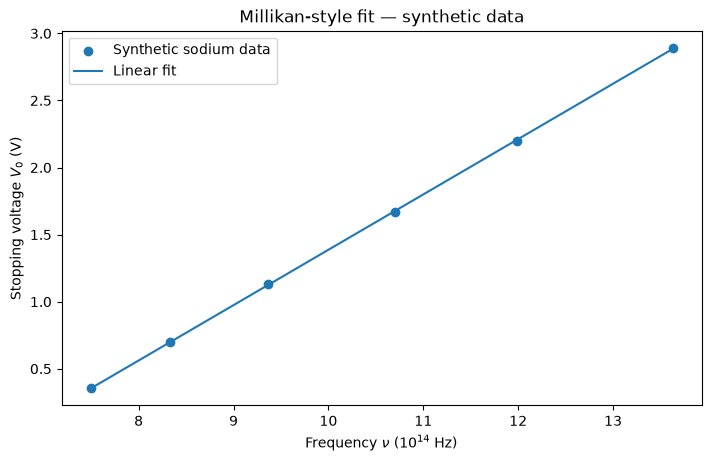

In [3]:
phi_ev = METALS["Na"]
wavelengths = np.array([220, 250, 280, 320, 360, 400]) * 1e-9
frequencies = c / wavelengths
assert np.all(h_ev * frequencies > phi_ev), "Use wavelengths below the metal's threshold."
noise_std_v = 0.01
rng = np.random.default_rng(1905)
voltages = h_ev * frequencies - phi_ev + rng.normal(0, noise_std_v, len(frequencies))

# Frequencies are in Hz and stopping voltages in V.
slope, intercept = np.polyfit(frequencies, voltages, 1)
h_fit, phi_fit_ev = slope * e, -intercept
assert abs(h_fit / h - 1) < 0.02
print(f"Synthetic fit: h = {h_fit:.8e} J s ({100 * (h_fit / h - 1):+.3f}%), phi = {phi_fit_ev:.4f} eV")
print(f"Inputs: h = {h:.8e} J s, phi = {phi_ev:.2f} eV")

fig, ax = plt.subplots(figsize=(7, 4.5), layout="constrained")
ax.scatter(frequencies / 1e14, voltages, label="Synthetic sodium data")
grid = np.linspace(frequencies.min(), frequencies.max(), 200)
ax.plot(grid / 1e14, slope * grid + intercept, label="Linear fit")
ax.set(xlabel=r"Frequency $\nu$ ($10^{14}$ Hz)", ylabel=r"Stopping voltage $V_0$ (V)",
       title="Millikan-style fit — synthetic data")
ax.legend()
plt.show()

## 4. Thử thêm / *Try this*

- Tăng `noise_std_v`: khi nào sai số của $h$ vượt 2 % và phép kiểm tra không còn đạt?
  *Increase `noise_std_v`: when does the error in $h$ exceed 2% and fail the assertion?*
- Giữ lại ít bước sóng hơn (ít nhất hai giá trị khác nhau): kết quả thay đổi ra sao?
  *Keep fewer wavelengths (at least two distinct values): how does the result change?*
- Chọn kim loại khác trong `METALS`, cập nhật nhãn đồ thị và chọn các bước sóng ngắn hơn bước sóng ngưỡng của nó.
  *Choose another metal in `METALS`, update the plot label, and use wavelengths below its threshold.*